(paramfit_emcee_ntbk)=

# Parameters fit with emcee

This is an example of how we can combine the **ASteCA** synthetic clusters with a likelihood defined by the user and an external MCMC sampler, here [emcee](https://emcee.readthedocs.io/) (the affine-invariant ensemble sampler of [Foreman-Mackey et al. 2013](https://ui.adsabs.harvard.edu/abs/2013PASP..125..306F)), to estimate the fundamental parameters of an observed cluster.

**ASteCA** includes its own sampler, with a built-in likelihood that was tested and calibrated with it (see the [Parameters fit with asteca.Sampler](paramfit_sampler_ntbk) tutorial). This tutorial shows instead how to use any other likelihood and sampler. emcee needs to be installed separately (`pip install emcee`); here's a list with many other Python-based [MCMC and ABC packages](https://gabriel-p.github.io/pythonMCMC/).

## Loading ASteCA objects

We start by instantiating an [Isochrones](asteca.Isochrones) object with a PARSEC isochrone. This is an example file but you can use whatever isochrone service fits your needs:

In [1]:
import asteca

# Load isochrones
isochs = asteca.Isochrones(
    model='parsec',
    isochs_path="../../_static/isochrones/parsec/",
    mag="Gmag",
    color=("G_BPmag", "G_RPmag"),
    magnitude_effl=6390.7,
    color_effl=(5182.58, 7825.08),
    verbose=2
)


Instantiating isochrones
Model          : PARSEC
N_files        : 1
N_mets         : 5
N_ages         : 13
N_points       : 2000
z    range     : [0.01, 0.03]
loga range     : [7.0, 10.0]
Magnitude      : Gmag
Color          : G_BPmag-G_RPmag
Isochrone object generated


Next we instantiate a [Synthetic](asteca.Synthetic) object, passing the `isochs` object we just created (we are using all defaults for the arguments here):

In [2]:
# Create Synthetic cluster object
synthcl = asteca.Synthetic(isochs, seed=457304, verbose=2)


Instantiating synthetic
(Tabulating IMF)
Default params : {'met': 0.0152, 'loga': 8.0, 'alpha': 0.09, 'beta': 0.94, 'Rv': 3.1, 'DR': 0.0, 'Av': 0.2, 'dm': 9.0}
Extinction law : CCMO
Diff reddening : foreground
IMF            : chabrier_2014
Gamma dist     : D&K
Random seed    : 457304
Synthetic clusters object generated


Now we load our observed cluster into a [Cluster](asteca.Cluster) object:

In [3]:
import pandas as pd

obs_df = pd.read_csv("../../_static/cluster.csv")

my_cluster = asteca.Cluster(
    ra=obs_df["RA_ICRS"],
    dec=obs_df["DE_ICRS"], 
    mag=obs_df["Gmag"],
    e_mag=obs_df["e_Gmag"],
    color=obs_df["BP-RP"],
    e_color=obs_df["e_BP-RP"],
    verbose=2
)


Instantiating cluster from data
Columns read   : ra, dec, mag, e_mag, color, e_color
N_stars        : 1428
N_nan_phot     : 9
N_clust_min    : 25
N_clust_max    : 2000
Cluster object generated


We assume that the cluster file loaded in `obs_df` is composed of only the most probable members of the cluster. If not, you can refer to the [Membership probabilities](membership) tutorial to learn how to obtain the membership probabilities and select the most probable members.

Finally, we need to calibrate our `synthcl` object with the `my_cluster` object we generated above. This adjusts the synthetic clusters to the observed one: same number of stars, maximum magnitude, and photometric uncertainties.

In [4]:
# Calibrate the `synthcl` object
synthcl.calibrate(my_cluster)


Calibrated observed cluster
N_stars_obs    : 1419
Max magnitude  : 18.99
Error distribution loaded


## Defining the priors

We are now ready to estimate the fundamental parameters with emcee. The first step is to define the priors for the parameters that are being estimated. The parameters that are *not* estimated keep the default values shown when the `synthcl` object was created.

emcee does not handle priors itself: they are part of the log-probability function that it samples (see below). We use uniform priors, i.e. a constant log-prior inside the ranges below and $-\infty$ outside of them.

In [5]:
import numpy as np

# Ranges for the fitted parameters
priors_dict = {
    "met": (0.01, 0.02),
    "loga": (7.0, 9.5),
    "dm": (8.0, 10.5),
    "Av": (0.0, 2.0),
}
names = list(priors_dict)
# Lower and upper limits of the uniform priors
p_min, p_max = np.array(list(priors_dict.values())).T

## Defining the likelihood

Next we define our own likelihood. Any function that compares the observed and synthetic clusters can be used here. We use the Poisson likelihood ratio of [Dolphin (2002)](https://ui.adsabs.harvard.edu/abs/2002MNRAS.332...91D), a common choice to compare a binned observed CMD (Hess diagram) with a model. The observed and synthetic stars are binned into a fixed Hess diagram (the CMD split into cells, spanning the observed cluster), and the log-likelihood is:

$$
\ln L = -\sum_i \left[m_i - n_i + n_i \ln\left(\frac{n_i}{m_i}\right)\right]
$$

where $n_i$ and $m_i$ are the number of observed and synthetic stars in cell $i$ (the last term is `0` when $n_i=0$). Its maximum value is `0`, obtained when $m_i=n_i$ in all the cells. Once calibrated, the `synthcl` object generates synthetic clusters with the same number of stars as the observed cluster, so the counts can be compared directly. Synthetic stars outside of the observed CMD do not fall in any cell, which lowers the likelihood. A small floor is added to $m_i$ to avoid $\ln(0)$ in the cells with observed stars and no synthetic stars.

The observed Hess diagram does not change during the run, so we compute it only once:

In [6]:
# Observed stars with valid photometry
msk = np.isfinite(my_cluster.mag) & np.isfinite(my_cluster.color)
obs_mag, obs_col = my_cluster.mag[msk], my_cluster.color[msk]

# Fixed Hess diagram, spanning the observed CMD
mag_edges = np.linspace(obs_mag.min(), obs_mag.max(), 21)
col_edges = np.linspace(obs_col.min(), obs_col.max(), 16)
n_obs = np.histogram2d(obs_mag, obs_col, bins=(mag_edges, col_edges))[0]
# Positions of the cells with observed stars, and the n*ln(n) term of these cells
nz = n_obs > 0
n_nz = n_obs[nz]
n_ln_n = n_nz * np.log(n_nz)
# Floor for the number of synthetic stars in a cell
m_floor = 0.1


def poisson_lkl(synth):
    """Poisson likelihood ratio (Dolphin 2002) between the observed cluster and a
    synthetic cluster, whose first two rows are its magnitude and color. The maximum
    value is 0 (same number of stars in every cell)."""
    if synth.size == 0:
        # Empty synthetic cluster
        m = np.zeros_like(n_obs)
    else:
        m = np.histogram2d(synth[0], synth[1], bins=(mag_edges, col_edges))[0]
    m_nz = np.maximum(m[nz], m_floor)
    # The cells with no observed stars only add their m_i term
    return -(m.sum() - m[nz].sum() + np.sum(m_nz - n_nz + n_ln_n - n_nz * np.log(m_nz)))

The log-likelihood function takes an array with the values of the fitted parameters, in the same order as the priors above. With `vectorize=True` (see below) emcee passes the positions of half of the walkers in a single call (the walkers are moved in two halves), as an array of shape `(n_walkers / 2, n_params)`. These are generated at once with the `batch=True` argument of the [generate()](asteca.Synthetic.generate) method, which returns the same synthetic clusters as generating each set of parameters separately. With [numba](https://numba.pydata.org/) installed it removes the Python overhead of each synthetic cluster (**without numba there is no speedup**). The first call includes the compilation of the numba functions, which are then cached for later sessions.

A likelihood computed with all the stars treats the synthetic clusters as an exact model of the observed one. This is not the case for a real cluster, and for clusters with many members the uncertainties of the parameters can be too small. A simple way to account for this is to divide the log-likelihood by a `temperature` $T>1$, which widens the posterior by a factor of about $\sqrt{T}$. We set it with the same rule that `asteca.Sampler` uses with `temperature="auto"`: $T=1$ for $N\leq 150$, $T=2$ for $150<N\leq 400$, and $T=4$ above. This rule was calibrated for the built-in likelihood of `asteca.Sampler`, not for this one, so it is only used here as an example: the users should choose a value suited to their own likelihood and data.

The log-probability sampled by emcee is the sum of the log-prior and the log-likelihood. The synthetic clusters are only generated for the walkers inside the priors:

In [7]:
# Temperature as a function of the number of members, as (max N, temperature)
# pairs: the first pair with N <= max N applies
N_temperatures = ((150, 1.0), (400, 2.0), (np.inf, 4.0))
temperature = next(T for N_max, T in N_temperatures if obs_mag.size <= N_max)
print(f"N={obs_mag.size}, temperature={temperature:g}")


def log_like(params_arr):
    """Log-likelihood of an array of fitted parameters, of shape (N, n_params)"""
    # Generate one synthetic cluster per set of parameters
    synth_list = synthcl.generate(dict(zip(names, params_arr.T)), batch=True)
    # Tempered log-likelihood of each synthetic cluster (0 means a perfect match)
    lnl = np.array([poisson_lkl(synth) for synth in synth_list]) / temperature
    # Non-finite values are not expected; reject them as a safety check
    lnl[~np.isfinite(lnl)] = -np.inf
    return lnl


def log_prob(params_arr):
    """Log-probability (uniform log-prior plus log-likelihood) of an array of fitted
    parameters, of shape (N, n_params)"""
    lnp = np.full(len(params_arr), -np.inf)
    # Walkers inside the priors
    inside = np.all((params_arr >= p_min) & (params_arr <= p_max), axis=1)
    if inside.any():
        lnp[inside] = log_like(params_arr[inside])
    return lnp

N=1419, temperature=4


## Initial positions of the walkers

emcee moves a set of walkers through the parameter space. If they start spread over the whole prior, some of them can take a long time to reach the posterior, or get stuck in a secondary maximum of the likelihood for the whole run (a walker in a low probability region can not move to the main maximum if all the other walkers are far from it). As recommended in the emcee docs, we start all the walkers in a small ball around the best set of parameters found. To find it, we evaluate a few thousand random sets of parameters drawn from the priors and keep the best one (a proper optimization can be used instead):

In [8]:
n_walkers, n_params = 32, len(names)

rng = np.random.default_rng(457304)
# Random draws from the priors, and their log-probabilities
draws = rng.uniform(p_min, p_max, size=(2000, n_params))
lnp_draws = log_prob(draws)
p_best = draws[np.argmax(lnp_draws)]
print("Best draw:", ", ".join(f"{k}={v:.3f}" for k, v in zip(names, p_best)))

# Start the walkers in a small ball around the best draw (0.1% of the prior ranges),
# within the priors
p0 = p_best + 1e-3 * (p_max - p_min) * rng.normal(size=(n_walkers, n_params))
p0 = np.clip(p0, p_min, p_max)

Best draw: met=0.019, loga=8.211, dm=8.042, Av=0.138


## Running emcee

We create an [EnsembleSampler](https://emcee.readthedocs.io/en/stable/user/sampler/) with 32 walkers (eight per fitted parameter) and the log-probability function, and fix the state of its random number generator for reproducibility. We use its default move (the affine-invariant "stretch" move); emcee's differential evolution moves mix faster in this problem, but their walkers contract into a too narrow posterior on this likelihood. We run 10000 steps per walker, which takes a couple of minutes:

In [9]:
import emcee
import time

sampler = emcee.EnsembleSampler(n_walkers, n_params, log_prob, vectorize=True)
# Fix the random state of the sampler
sampler.random_state = np.random.RandomState(457304).get_state()

t0 = time.perf_counter()
sampler.run_mcmc(p0, 10000, progress=False)
print(f"Run time: {time.perf_counter() - t0:.1f} s")

Run time: 148.7 s


## Convergence

Unlike the [asteca.Sampler](paramfit_sampler_ntbk) or pyABC runs, an MCMC run has no stopping criterion: we need to check that the walkers have converged. The mean acceptance fraction of the moves should be roughly between 0.2 and 0.5. The integrated autocorrelation time $\tau$ of each parameter is the number of steps needed to obtain an independent sample (see the emcee docs on [autocorrelation analysis](https://emcee.readthedocs.io/en/stable/tutorials/autocorr/)). The first steps, while the walkers move towards the posterior (burn-in), are discarded.

The likelihood of the synthetic clusters is not smooth (small changes in the parameters move stars across the cells of the Hess diagram), which makes $\tau$ large: a few hundred steps. emcee recommends chains longer than about $50\tau$ for a reliable estimate of $\tau$, and warns if they are shorter. We silence the warning and print the length of our chain in units of $\tau$ instead:

In [10]:
import logging

# Steps discarded as burn-in
burn = 1000

print(f"Mean acceptance fraction: {sampler.acceptance_fraction.mean():.2f}")
# Silence the warning for chains shorter than 50 tau
logging.getLogger("emcee").setLevel(logging.ERROR)
tau = sampler.get_autocorr_time(discard=burn, quiet=True)
n_steps = sampler.iteration - burn
for k, t in zip(names, tau):
    print(f"tau {k:<5}: {t:.0f} steps (chain length: {n_steps / t:.0f} tau)")

Mean acceptance fraction: 0.24


tau met  : 431 steps (chain length: 21 tau)
tau loga : 348 steps (chain length: 26 tau)
tau dm   : 478 steps (chain length: 19 tau)
tau Av   : 319 steps (chain length: 28 tau)


The position of each walker along the run (its trace) shows the burn-in (shaded), after which the walkers move around the same values:

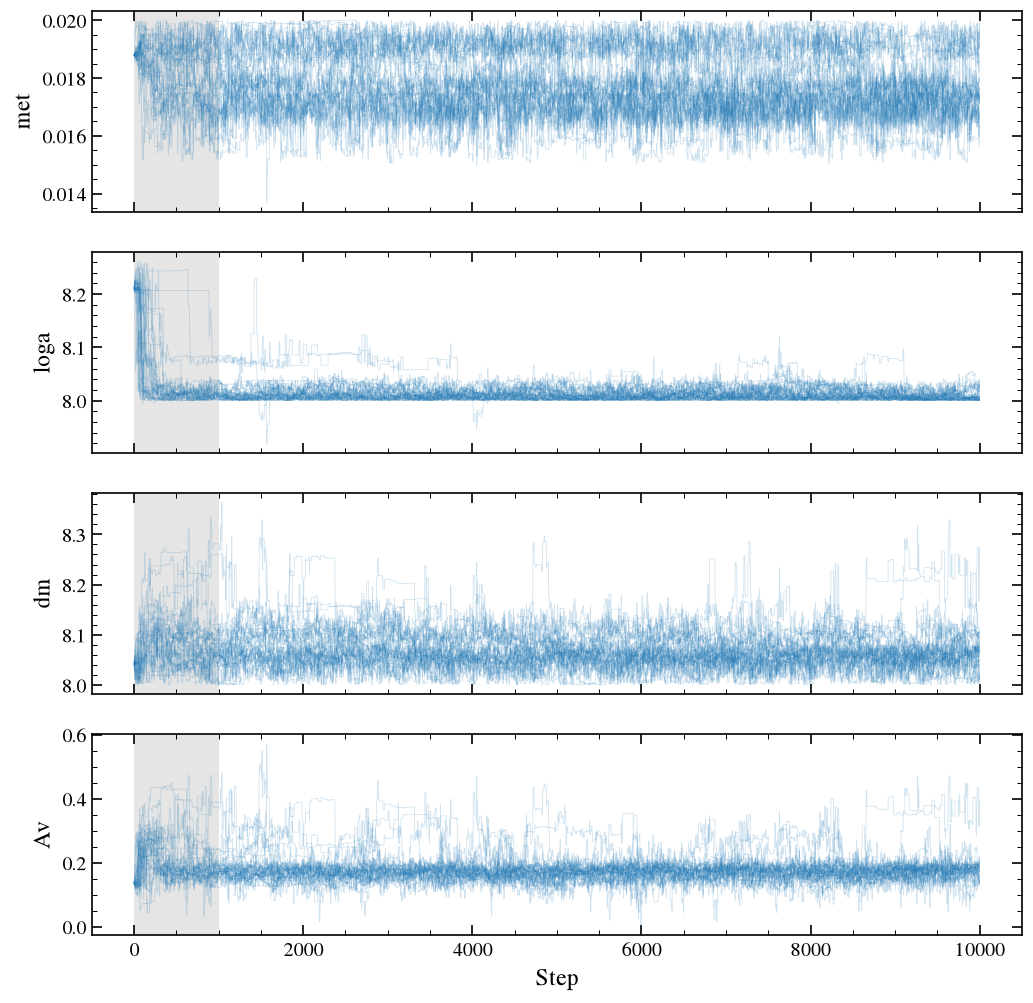

In [11]:
import matplotlib.pyplot as plt

# Common style of the plots in these tutorials
plt.style.use("../../_static/asteca.mplstyle")

chain = sampler.get_chain()
fig, axes = plt.subplots(n_params, 1, figsize=(10, 10), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(chain[:, :, i], c="C0", alpha=0.2, lw=0.5)
    ax.axvspan(0, burn, color="grey", alpha=0.2, lw=0)
    ax.set_ylabel(names[i])
axes[-1].set_xlabel("Step");

A simple check of convergence for a chain shorter than $50\tau$ is to compare the medians and standard deviations of the parameters in the first and second halves of the chain (after the burn-in). If the walkers have converged both halves sample the same distribution, and the values should agree:

In [12]:
chain = sampler.get_chain(discard=burn)
half = chain.shape[0] // 2
for label, part in (("first half ", chain[:half]), ("second half", chain[half:])):
    flat = part.reshape(-1, n_params)
    meds = ", ".join(f"{k}={m:.3f}" for k, m in zip(names, np.median(flat, axis=0)))
    stds = ", ".join(f"{s:.3f}" for s in flat.std(axis=0))
    print(f"{label}: {meds} (std: {stds})")

first half : met=0.018, loga=8.010, dm=8.065, Av=0.171 (std: 0.001, 0.017, 0.039, 0.044)
second half: met=0.017, loga=8.009, dm=8.060, Av=0.173 (std: 0.001, 0.012, 0.035, 0.037)


## Extracting the results

The posterior samples are the positions of all the walkers after the burn-in, keeping one every $\tau/2$ steps (thinning), since consecutive steps are correlated. The estimations for each fitted parameter are obtained from these samples:

In [13]:
# Posterior samples: burn-in discarded, thinned by half the largest autocorrelation time
thin = int(0.5 * tau.max())
samples = sampler.get_chain(discard=burn, thin=thin, flat=True)
print(f"Number of samples: {len(samples)}")

print("\nParameters estimation:")
print("----------------------")
fit_params = {}
for i, k in enumerate(names):
    # Extract medians for the fitted parameters
    _median = np.median(samples[:, i])
    fit_params[k] = _median
    # Extract STDDEV for the fitted parameters
    _std = np.std(samples[:, i])
    print("{:<5}: {:.3f} +/- {:.3f}".format(k, _median, _std))

Number of samples: 1184

Parameters estimation:
----------------------
met  : 0.018 +/- 0.001
loga : 8.010 +/- 0.014
dm   : 8.063 +/- 0.037
Av   : 0.171 +/- 0.040


emcee does not include its own plotting functions for the posterior, but the samples can be passed to any package. As in the other tutorials, we use [corner](https://corner.readthedocs.io/) to show the 1D and 2D posterior distributions:

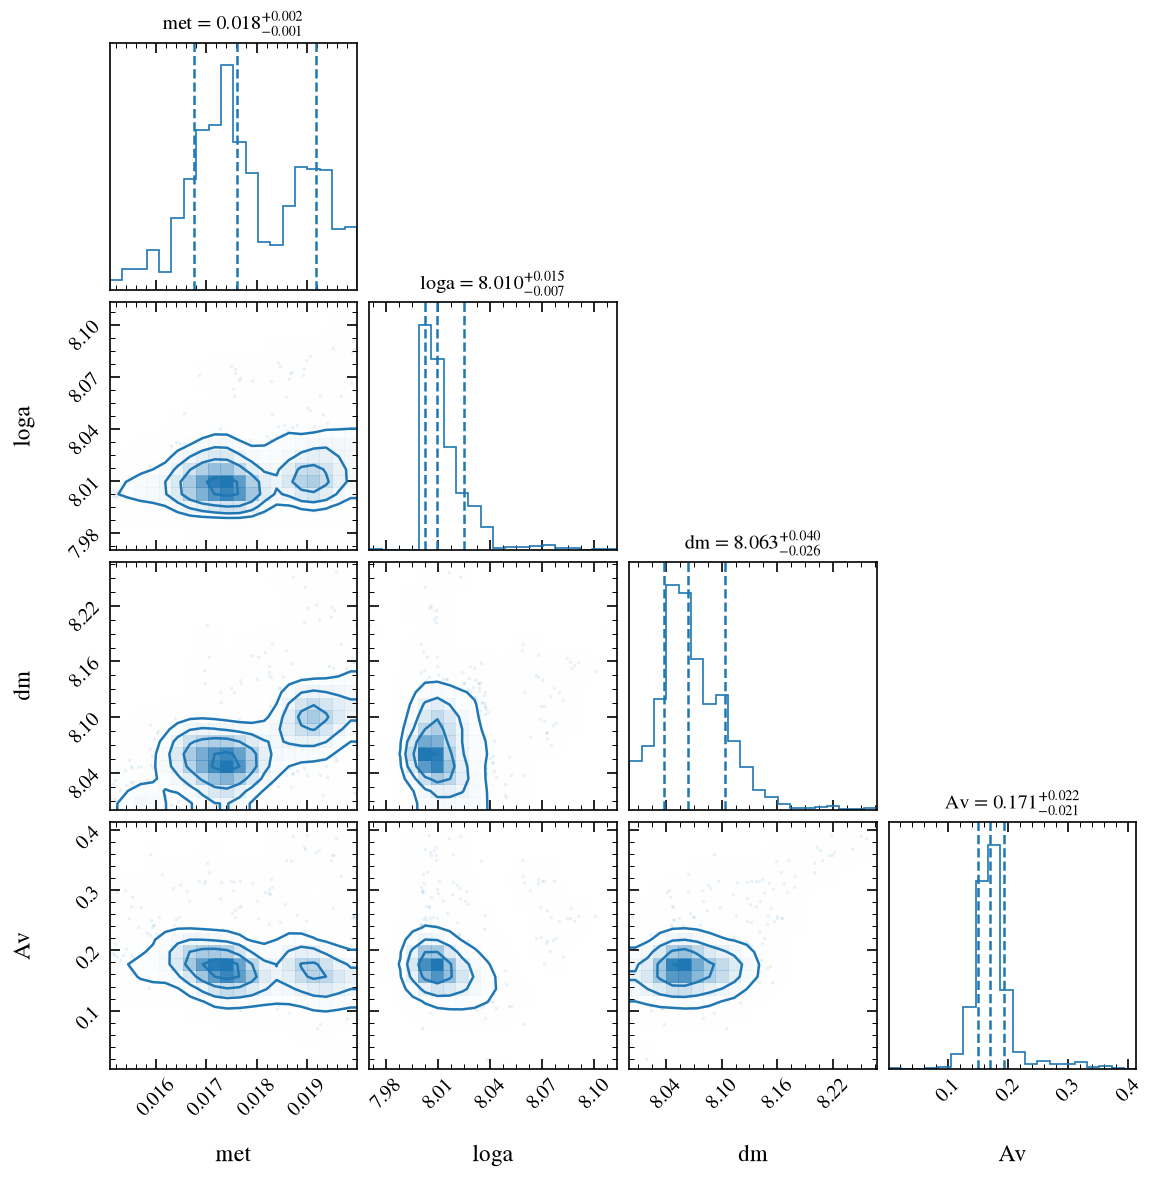

In [14]:
import corner

fig = plt.figure(figsize=(10, 10))
corner.corner(
    samples,
    fig=fig,
    labels=names,
    quantiles=(0.16, 0.5, 0.84),
    show_titles=True,
    title_fmt=".3f",
    color="C0",
    smooth=1.0,
    label_kwargs={"fontsize": 14},
    title_kwargs={"fontsize": 12},
);

These values need not match those of the [Parameters fit with asteca.Sampler](paramfit_sampler_ntbk) tutorial: the likelihood used here (a fixed Hess diagram, with a different binning) is not the one built into `asteca.Sampler`, and the temperature rule was not calibrated for it.

See the [Goodness of fit](paramfit_gof_ntbk) tutorial to assess whether the synthetic cluster generated with these parameters is a good representation of the observed cluster.